# Meta Horizon Worlds CCU: daily tables (Phase 1 prototype)

**Question:** is Meta Horizon growing, or staying small?

**Source:** `s3://srs-vendors/72degree/metahorizon/data/detail/`. 72degree scrapes the horizon.meta.com homepage 4x/day (00/06/12/18 **UTC** slots). Each scrape covers the ~64 worlds in Meta's *Popular* + *Hangout* lists, with per-world CCU summed across all instances of the world.

**Caveats:**
- Coverage is curated and rotating; there is no platform-wide total.
- **The series starts on 2026-10-14.** Before that, the vendor scraped world detail pages (CCU) once a day and re-published that data in later runs. `drop_stale_scrapes()` removes any scrape whose CCU exactly repeats the previous one; this catches `2026-10-14-06`, which was published before the fix.
- CCU swings strongly with time of day (about 3.4x between the 00 and 06 UTC slots), so only same-slot comparisons are meaningful.

**Outputs** (prototypes of the planned `SRS_MCP.META` views):
- `HORIZON_WORLDS_DAILY`: one row per date and world, with `avg_ccu`, `max_ccu` and `n_snapshots`.
- `HORIZON_PLATFORM_DAILY`: one row per calendar day. A day with no scrapes shows `n_snapshots = 0` and null metrics.
  - `total_ccu_avg` / `total_ccu_max`: the average and the max of each scrape's total.
  - Top-10 and top-30 sums, ranked separately by daily max and by daily average. Only worlds present in **every** scrape that day are eligible.
  - A chain-linked `panel_index`, 100 at the start date. Each day is compared with its *anchor*, the last day with a valid index, on matching (world, slot) pairs. A slot only counts if its scrape started within 15 min of the same slot on the anchor day (`MAX_SLOT_DRIFT_MIN`). With no comparable pairs, the index is **null** and the chain resumes from the anchor later.

All transform logic lives in `horizon_daily.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from horizon_daily import load_snapshots, build_worlds_daily, build_platform_daily, drop_stale_scrapes

pd.set_option("display.width", 200, "display.max_columns", 30)
snap = load_snapshots()
print("stale scrapes dropped:", [f"{d:%Y-%m-%d}-{s:02d}" for d, s in snap.attrs["stale_scrapes"]])
snap.groupby(["date", "slot", "file_name"]).agg(
    n_worlds=("world_id", "nunique"), total_ccu=("ccu", "sum"),
    scraped_from=("scraped_at_utc", "min"), scraped_to=("scraped_at_utc", "max"))

stale scrapes dropped: ['2026-10-14-06', '2026-10-14-12', '2026-10-14-18']


n_worlds  total_ccu        scraped_from          scraped_to
date       slot file_name                                                                                        
2026-10-14 0    metahorizon_detail_2026-10-14-00.csv        64        726 2026-10-14 00:00:06 2026-10-14 00:01:43
2026-10-15 0    metahorizon_detail_2026-10-15-00.csv        63        616 2026-10-15 00:00:08 2026-10-15 00:02:33
           6    metahorizon_detail_2026-10-15-06.csv        63        261 2026-10-15 06:00:07 2026-10-15 06:02:19

## Raw data checks

In [2]:
checks = {
    "rows": len(snap),
    "duplicate (date, slot, world)": snap.duplicated(["date", "slot", "world_id"]).sum(),
    "share of worlds with ccu = 0": round((snap.ccu == 0).mean(), 3),
    "rows with ccu > capacity (multi-instance)": int((snap.ccu > snap.capacity).sum()),
    "null ccu": int(snap.ccu.isna().sum()),
}
pd.Series(checks)

rows                                         190.000
duplicate (date, slot, world)                  0.000
share of worlds with ccu = 0                   0.226
rows with ccu > capacity (multi-instance)     59.000
null ccu                                       0.000
dtype: float64

## HORIZON_WORLDS_DAILY

In [3]:
worlds = build_worlds_daily(snap)
worlds.sort_values(["date", "max_ccu"], ascending=[True, False]).head(20)

,date,world_id,world_name,owner_name,avg_ccu,max_ccu,n_snapshots
10,2026-10-14,489075530784006,Pizza Kitchen,MetaHorizon,87.0,87,1
43,2026-10-14,8201876933160366,Spin the Bottle,Illuminated Studios,62.0,62,1
9,2026-10-14,462305146410908,Vr High School ✅,Copper Chosen vr,43.0,43,1
7,2026-10-14,452809350884397,Freddy's Hide and Seek,JoeBear79,42.0,42,1
3,2026-10-14,393502540519645,Super Boxing Gym,MetaHorizon,38.0,38,1
28,2026-10-14,838797812285547,FNAF Hide & Seek,JoeBear79,37.0,37,1
40,2026-10-14,3713380242015344,Action Island,5andw1ch,28.0,28,1
22,2026-10-14,733399513180174,Shovel Up!,BigBox Studio,27.0,27,1
12,2026-10-14,585586207888057,Idle Wild West Tycoon (Early Access),Puzzleroo,26.0,26,1
27,2026-10-14,822978224228706,Short & EZ Obby (FREE CAP),CherryOceanGames,25.0,25,1


## HORIZON_PLATFORM_DAILY

In [4]:
platform = build_platform_daily(snap, worlds)
platform

,date,n_snapshots,n_worlds,total_ccu_avg,total_ccu_max,top10_ccu_avg,top10_ccu_max,top30_ccu_avg,top30_ccu_max,panel_index,n_matched_slots,n_matched_worlds
0,2026-10-14,1,64,726.0,726,415.0,415,650.0,650,100.000000,<NA>,<NA>
1,2026-10-15,2,63,438.5,616,266.5,372,404.5,570,89.133627,1,52


## Trend charts

These charts only become informative once several days of scrapes have landed.

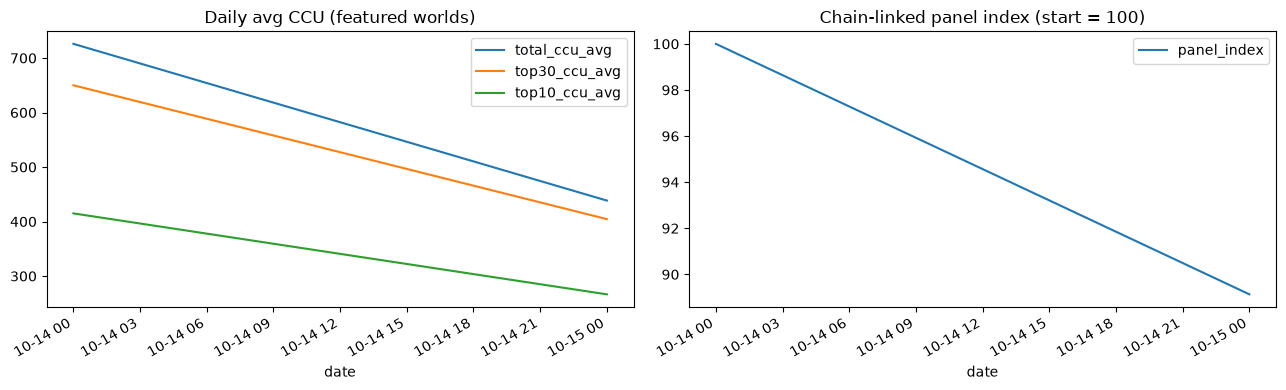

In [5]:
if platform["date"].nunique() > 1:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    platform.plot(x="date", y=["total_ccu_avg", "top30_ccu_avg", "top10_ccu_avg"], ax=axes[0], title="Daily avg CCU (featured worlds)")
    platform.plot(x="date", y="panel_index", ax=axes[1], title="Chain-linked panel index (start = 100)")
    plt.tight_layout()
else:
    print("Only one day of data so far; charts will render once more scrapes land.")

## Logic checks on synthetic data

These checks use the worked example from planning: world 1 = [0, 6, 24, 18] gives max 24 and avg 12; world 2 = [3, 14, 12, 8] gives max 14 and avg 9.25.
- World 3 appears in one scrape only, so it is excluded from the top-N sums. It still counts in `total_ccu_*`.
- On 10-15 the 00 slot ran 90 min late, so only the 06 slot is comparable. World 1 goes from 6 to 12, so the index reads **200**.
- 10-16 has no scrapes: the row exists with `n_snapshots = 0` and a null index.
- On 10-17 the 06 slot is compared with the anchor (10-15): worlds 1 + 4 go from 21 to 42, so the index reads **400**.
- On 10-18 the only scrape ran 20 min late, so the index is **null** and the anchor stays at 10-17.
- On 10-19 the 06 slot is compared with 10-17: 42 to 84, so the index reads **800**.
- Stale guard: a scrape that repeats the previous scrape's CCU across at least 10 non-zero worlds is dropped.

In [6]:
def scrape(date, slot, ccu_by_world, late_min=0):
    t = pd.Timestamp(date) + pd.Timedelta(hours=int(slot), minutes=int(late_min))
    return [(date, slot, w, v, t) for w, v in ccu_by_world.items()]

rows = []
for s, (v1, v2) in zip([0, 6, 12, 18], [(0, 3), (6, 14), (24, 12), (18, 8)]):
    rows += scrape("2026-10-14", s, {1: v1, 2: v2})
rows += [("2026-10-14", 0, 3, 50, pd.Timestamp("2026-10-14 00:00"))]
rows += scrape("2026-10-15", 0, {1: 5, 4: 9}, late_min=90) + scrape("2026-10-15", 6, {1: 12, 4: 9})
rows += scrape("2026-10-17", 6, {1: 33, 4: 9})
rows += scrape("2026-10-18", 6, {1: 30, 4: 9}, late_min=20)
rows += scrape("2026-10-19", 6, {1: 75, 4: 9})
toy = pd.DataFrame(rows, columns=["date", "slot", "world_id", "ccu", "scraped_at_utc"]).assign(
    date=lambda d: pd.to_datetime(d.date), world_name="w", owner_name="o")
toy_w = build_worlds_daily(toy)
toy_p = build_platform_daily(toy, toy_w).set_index("date")
w = toy_w.set_index(["date", "world_id"])
assert w.loc[("2026-10-14", 1), ["avg_ccu", "max_ccu"]].tolist() == [12, 24]
assert w.loc[("2026-10-14", 2), ["avg_ccu", "max_ccu"]].tolist() == [9.25, 14]
assert toy_p.loc["2026-10-14", ["total_ccu_max", "top10_ccu_max", "top10_ccu_avg"]].tolist() == [53, 38, 21.25]
assert toy_p.loc["2026-10-15", "panel_index"] == 200 and toy_p.loc["2026-10-15", "n_matched_slots"] == 1
assert toy_p.loc["2026-10-16", "n_snapshots"] == 0 and pd.isna(toy_p.loc["2026-10-16", "panel_index"])
assert toy_p.loc["2026-10-17", "panel_index"] == 400
assert pd.isna(toy_p.loc["2026-10-18", "panel_index"]) and toy_p.loc["2026-10-18", "n_matched_slots"] == 0
assert toy_p.loc["2026-10-19", "panel_index"] == 800

# stale guard: 12 non-zero worlds, the 12 slot re-publishes the 06 slot
base = {w: w + 1 for w in range(12)}
stale_toy = pd.DataFrame(scrape("2026-10-14", 6, base) + scrape("2026-10-14", 12, base) + scrape("2026-10-14", 18, {w: v + 1 for w, v in base.items()}),
                         columns=["date", "slot", "world_id", "ccu", "scraped_at_utc"]).assign(date=lambda d: pd.to_datetime(d.date))
assert drop_stale_scrapes(stale_toy).attrs["stale_scrapes"] == [(pd.Timestamp("2026-10-14"), 12)]
toy_p[["n_snapshots", "total_ccu_avg", "panel_index", "n_matched_slots", "n_matched_worlds"]]

C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_56804\4029329152.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  t = pd.Timestamp(date) + pd.Timedelta(hours=int(slot), minutes=int(late_min))
C:\Users\fintan.creedon\AppData\Local\Temp\ipykernel_56804\4029329152.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  t = pd.Timestamp(date) + pd.Timedelta(hours=int(slot), minutes=int(late_min))


,n_snapshots,total_ccu_avg,panel_index,n_matched_slots,n_matched_worlds
date,,,,,
2026-10-14,4,33.75,100.0,<NA>,<NA>
2026-10-15,2,17.50,200.0,1,1
2026-10-16,0,NaN,NaN,NaN,NaN
2026-10-17,1,42.00,400.0,1,2
2026-10-18,1,39.00,<NA>,0,0
2026-10-19,1,84.00,800.0,1,2
